In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Se pide, usando regresión lineal:

Dibujar con una línea la relación que hay entre la altura y la edad de los alumnos de esta clase: 

In [2]:
lista_alumnos = [("Leonardo S", 24, 1.82), 
                 ("Piero T", 25, 1.71), 
                 ("Marta B", 35, 1.66), 
                 ("Silvia P", 37, 1.63), 
                 ("Faro Z", 29, 1.90), 
                 ("Miguel N", 27, 1.80), 
                 ("Alejandro M", 28, 1.70), 
                 ("Cristina M", 32, 1.60), 
                 ("Francisco P", 36, 1.74), 
                 ("Jorge D", 45, 1.72), 
                 ("Jesús L", 41, 1.65), 
                 ("Marta G", 30, 1.65), 
                 ("Jennifer S", 40, 1.60), 
                 ("Diego I", 39, 1.80), 
                 ("Antonio C", 23, 1.77), 
                 ("Juan M", 32, 1.75), 
                 ("David S", 27, 1.70), 
                 ("Antonio J", 34, 1.80), 
                 ("Carlos H", 27, 1.77), 
                 ("Erik U", 28, 1.70), 
                 ("Marcos L", 35, 1.80)] 

### ¿Es una buena técnica para este tipo de problemas? Demuéstralo antes de entrenar un modelo con un análisis descriptivo.

In [3]:
df = pd.DataFrame(lista_alumnos, columns= ["nombre", "edad", "altura"])
df

,nombre,edad,altura
0,Leonardo S,24,1.82
1,Piero T,25,1.71
2,Marta B,35,1.66
3,Silvia P,37,1.63
4,Faro Z,29,1.90
5,Miguel N,27,1.80
6,Alejandro M,28,1.70
7,Cristina M,32,1.60
8,Francisco P,36,1.74
9,Jorge D,45,1.72


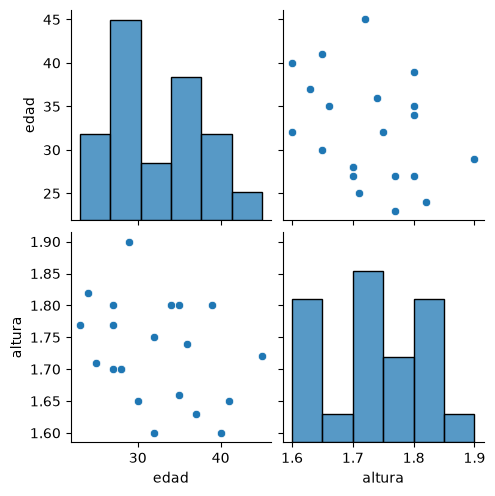

In [4]:
sns.pairplot(df)

### Entrena un modelo de regresión lineal

In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [6]:
X = df[['edad']]
X

,edad
0,24
1,25
2,35
3,37
4,29
5,27
6,28
7,32
8,36
9,45


In [7]:
y = df[['altura']]
y

,altura
0,1.82
1,1.71
2,1.66
3,1.63
4,1.90
5,1.80
6,1.70
7,1.60
8,1.74
9,1.72


In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 4, random_state= 42)

In [9]:
lr = LinearRegression()

In [10]:
lr.fit(X_train, y_train) # Entrena el modelo

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[-0.]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['edad']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[1.85]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


In [11]:
lr.intercept_ #Cuanto valdría la variable altura cuando todas las demás variables valen 0

array([1.85380957])

In [12]:
lr.coef_ #Cuanto cambia la estatura por cada unidad de edad

array([[-0.00415879]])

In [13]:
X_test

,edad
0,24
17,34
15,32
1,25


In [14]:
lr.predict(X_test)

array([[1.75399865],
       [1.71241077],
       [1.72072834],
       [1.74983986]])

### ¿Qué error se comete? Calcula los errores que está cometiendo tu modelo de forma manual con python. Aparte, usa las métricas de sklearn MAE, MAPE, MSE y el RMSE.

In [15]:
df_2 = df

In [32]:
df_2['prediccion'] = lr.predict(df_2[['edad']])
df_2['error'] = df_2['altura'] - lr.predict(df_2[['edad']]).ravel()
df_2['error cuad'] = df_2['error']**2
df_2

,nombre,edad,altura,prediccion,error,error cuad
0,Leonardo S,24,1.82,1.753999,0.066001,0.004356
1,Piero T,25,1.71,1.749840,-0.039840,0.001587
2,Marta B,35,1.66,1.708252,-0.048252,0.002328
3,Silvia P,37,1.63,1.699934,-0.069934,0.004891
4,Faro Z,29,1.90,1.733205,0.166795,0.027821
5,Miguel N,27,1.80,1.741522,0.058478,0.003420
6,Alejandro M,28,1.70,1.737363,-0.037363,0.001396
7,Cristina M,32,1.60,1.720728,-0.120728,0.014575
8,Francisco P,36,1.74,1.704093,0.035907,0.001289
9,Jorge D,45,1.72,1.666664,0.053336,0.002845


In [30]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, root_mean_squared_error, r2_score

In [23]:
y_pred = lr.predict(df_2[['edad']]) # Se predice la altura, pero nosotros ponemos la edad.

In [ ]:
mean_absolute_error(df_2[['altura']], y_pred)

0.06345888114072566

In [25]:
mean_absolute_percentage_error(df_2[['altura']], y_pred)

0.03663772184396239

In [26]:
mean_squared_error(df_2[['altura']], y_pred)

0.005346611421396251

In [ ]:
root_mean_squared_error(df_2[['altura']], y_pred)

0.07312052667614102

In [ ]:
r2_score(df_2[['altura']], y_pred) # Si el coeficiente es 0 es malo y si es 1 es perfecta la predicción. Eso no es realista que de 1

0.10053573020685669

<Axes: xlabel='edad', ylabel='altura'>

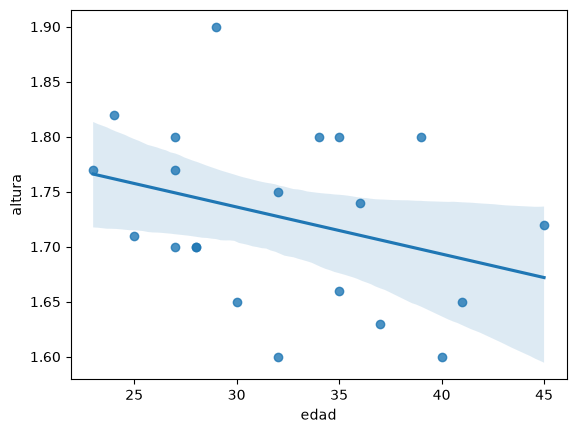

In [34]:
sns.regplot(x=df['edad'], y=df['altura'])